In [1]:
import pandas as pd
import numpy as np
import os
import joblib

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

from imblearn.over_sampling import SMOTE

In [2]:
PROJECT_DIR = os.path.abspath("..")

DATA_PATH = os.path.join(
    PROJECT_DIR,
    "data",
    "cleaned",
    "ChargingRecords_Featured.csv"
)

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (72826, 32)


,UserID,ChargerID,ChargerCompany,Location,ChargerType,StartDay,StartTime,EndDay,EndTime,StartDatetime,...,IsWeekend,DurationHours,DurationCategory,HourSin,HourCos,MonthSin,MonthCos,DayOfWeekSin,DayOfWeekCos,DemandCategory
0,0,1,1,hotel,0,2022-09-15,20:54:02,2022-09-15,23:59:13,2022-09-15 20:54:00,...,0,3.083333,Long,-0.866025,5.000000e-01,-1.0,-1.836970e-16,0.433884,-0.900969,High Demand
1,0,1,1,hotel,0,2022-09-14,20:01:05,2022-09-14,21:31:04,2022-09-14 20:01:00,...,0,1.500000,Medium,-0.866025,5.000000e-01,-1.0,-1.836970e-16,0.974928,-0.222521,Normal Demand
2,0,1,1,hotel,0,2022-09-14,18:54:30,2022-09-14,19:54:29,2022-09-14 18:54:00,...,0,1.000000,Short,-1.000000,-1.836970e-16,-1.0,-1.836970e-16,0.974928,-0.222521,Normal Demand
3,0,1,1,hotel,0,2022-09-29,18:32:51,2022-09-30,0:16:42,2022-09-29 18:32:00,...,0,5.733333,Very Long,-1.000000,-1.836970e-16,-1.0,-1.836970e-16,0.433884,-0.900969,High Demand
4,0,1,1,hotel,0,2022-09-25,19:30:15,2022-09-26,0:30:14,2022-09-25 19:30:00,...,1,5.000000,Very Long,-0.965926,2.588190e-01,-1.0,-1.836970e-16,-0.781831,0.623490,High Demand


In [4]:
# Check Target Variable
print("Demand Category Distribution:")

print(df["DemandCategory"].value_counts())

print("\nDemand Category Percentage:")

print(
    df["DemandCategory"].value_counts(normalize=True) * 100
)

Demand Category Distribution:
DemandCategory
High Demand      36439
Normal Demand    36387
Name: count, dtype: int64

Demand Category Percentage:
DemandCategory
High Demand      50.035702
Normal Demand    49.964298
Name: proportion, dtype: float64


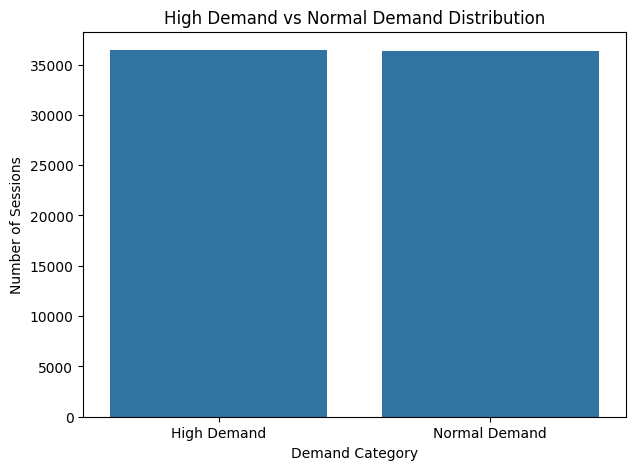

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="DemandCategory"
)

plt.title("High Demand vs Normal Demand Distribution")

plt.xlabel("Demand Category")

plt.ylabel("Number of Sessions")

plt.show()

In [6]:
target = "DemandCategory"

drop_columns = [
    "Demand",
    "DemandCategory",
    "UserID",
    "ChargerID",
    "StartDay",
    "StartTime",
    "EndDay",
    "EndTime",
    "StartDatetime",
    "EndDatetime",
    "CalculatedDuration"
]

X = df.drop(
    columns=drop_columns,
    errors="ignore"
)

# Encode target variable
y = df[target].map({
    "Normal Demand": 0,
    "High Demand": 1
})

print("Target Distribution:")

print(y.value_counts())

print("\nTarget Mapping:")
print("Normal Demand = 0")
print("High Demand = 1")

Target Distribution:
DemandCategory
1    36439
0    36387
Name: count, dtype: int64

Target Mapping:
Normal Demand = 0
High Demand = 1


In [7]:
categorical_columns = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

for column in ["ChargerCompany", "ChargerType"]:
    if column in X.columns and column not in categorical_columns:
        categorical_columns.append(column)

numerical_columns = [
    column for column in X.columns
    if column not in categorical_columns
]

print("Numerical Features:", numerical_columns)

print("\nCategorical Features:", categorical_columns)

Numerical Features: ['Duration', 'Year', 'Month', 'Day', 'DayOfWeek', 'WeekOfYear', 'Quarter', 'Hour', 'Minute', 'IsWeekend', 'DurationHours', 'HourSin', 'HourCos', 'MonthSin', 'MonthCos', 'DayOfWeekSin', 'DayOfWeekCos']

Categorical Features: ['Location', 'DurationCategory', 'ChargerCompany', 'ChargerType']


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

print("\nTraining Target Distribution:")

print(y_train.value_counts(normalize=True))

Training Data: (58260, 21)
Testing Data: (14566, 21)

Training Target Distribution:
DemandCategory
1    0.50036
0    0.49964
Name: proportion, dtype: float64


In [9]:
# Preprocessing Pipeline
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_columns),
        ("cat", categorical_transformer, categorical_columns)
    ]
)

In [10]:
# Classification Models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        probability=True,
        random_state=42
    )
}

In [11]:
# XG Boost and Light GBM
try:
    from xgboost import XGBClassifier

    models["XGBoost"] = XGBClassifier(
        n_estimators=100,
        max_depth=6,
        learning_rate=0.1,
        random_state=42,
        eval_metric="logloss",
        n_jobs=-1
    )

except ImportError:
    print("XGBoost is not installed.")


try:
    from lightgbm import LGBMClassifier

    models["LightGBM"] = LGBMClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42,
        verbosity=-1,
        n_jobs=-1
    )

except ImportError:
    print("LightGBM is not installed.")


print("Models Available:")

print(list(models.keys()))

Models Available:
['Logistic Regression', 'Decision Tree', 'Random Forest', 'KNN', 'SVM', 'XGBoost', 'LightGBM']


In [12]:
# Train Models with SMOTE
trained_models = {}

for name, model in models.items():

    print("\nTraining:", name)

    pipeline = ImbPipeline(steps=[
        ("preprocessor", preprocessor),
        ("smote", SMOTE(random_state=42)),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(name, "Training Completed")


Training: Logistic Regression
Logistic Regression Training Completed

Training: Decision Tree
Decision Tree Training Completed

Training: Random Forest
Random Forest Training Completed

Training: KNN
KNN Training Completed

Training: SVM


c:\Users\yendl\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM Training Completed

Training: XGBoost
XGBoost Training Completed

Training: LightGBM
LightGBM Training Completed


In [13]:
results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({

        "Model": name,

        "Accuracy": accuracy_score(y_test, y_pred),

        "Precision": precision_score(
            y_test,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "F1 Score": f1_score(
            y_test,
            y_pred,
            pos_label=1,
            zero_division=0
        ),

        "ROC AUC": roc_auc_score(
            y_test,
            y_prob
        )
    })


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC
2,Random Forest,0.900316,0.877881,0.930159,0.903264,0.958800
6,LightGBM,0.898462,0.872898,0.932903,0.901904,0.960439
5,XGBoost,0.898394,0.872690,0.933041,0.901857,0.960432
4,SVM,0.885487,0.841102,0.950741,0.892567,0.943515
0,Logistic Regression,0.840656,0.776528,0.956915,0.857336,0.909040
1,Decision Tree,0.850886,0.857063,0.842481,0.849709,0.850891
3,KNN,0.828779,0.801509,0.874314,0.836330,0.898914


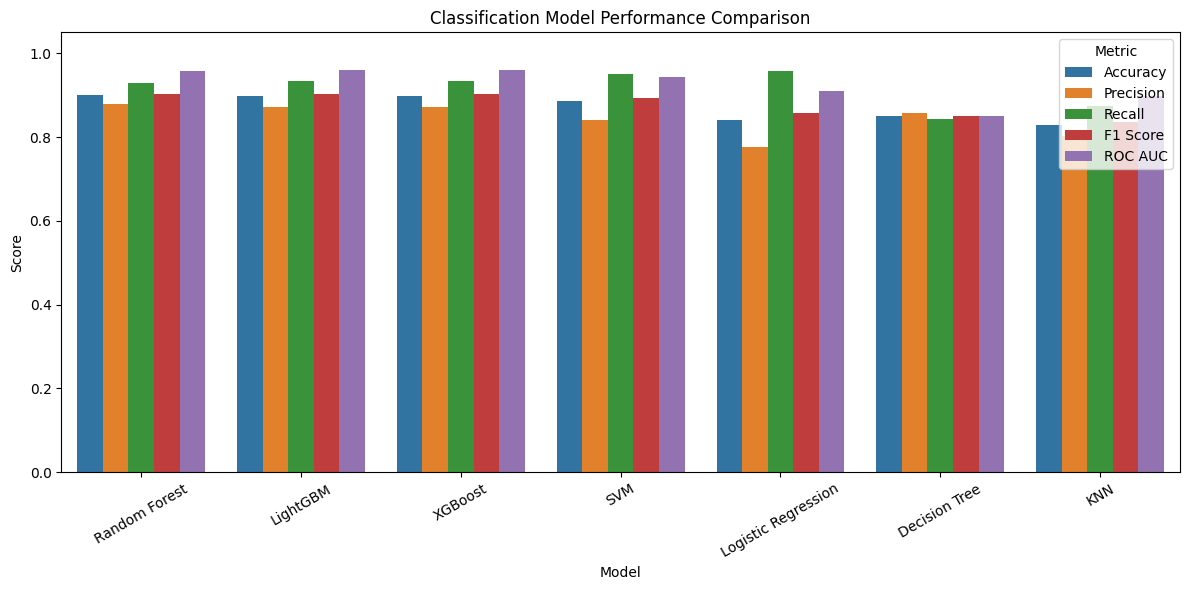

In [14]:
plt.figure(figsize=(12, 6))

results_melted = results_df.melt(
    id_vars="Model",
    value_vars=[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(
    data=results_melted,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Classification Model Performance Comparison")

plt.xticks(rotation=30)

plt.ylim(0, 1.05)

plt.tight_layout()

plt.show()

In [15]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best Classification Model:", best_model_name)

print(
    "Best F1 Score:",
    results_df.iloc[0]["F1 Score"]
)

Best Classification Model: Random Forest
Best F1 Score: 0.9032644903397735


In [16]:
y_pred_best = best_model.predict(X_test)

print(
    classification_report(
        y_test,
        y_pred_best,
        labels=[0, 1],
        target_names=[
            "Normal Demand",
            "High Demand"
        ],
        zero_division=0
    )
)

               precision    recall  f1-score   support

Normal Demand       0.93      0.87      0.90      7278
  High Demand       0.88      0.93      0.90      7288

     accuracy                           0.90     14566
    macro avg       0.90      0.90      0.90     14566
 weighted avg       0.90      0.90      0.90     14566



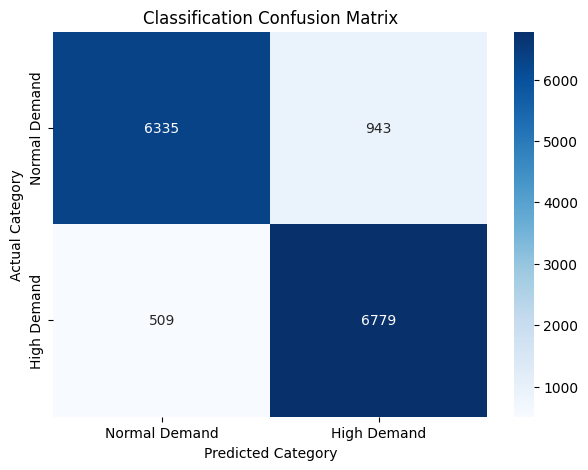

In [17]:
cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Normal Demand",
        "High Demand"
    ],
    yticklabels=[
        "Normal Demand",
        "High Demand"
    ]
)

plt.title("Classification Confusion Matrix")

plt.xlabel("Predicted Category")

plt.ylabel("Actual Category")

plt.show()

In [18]:
results_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "classification_model_comparison.csv"
    ),
    index=False
)

print("Classification Results Saved Successfully!")

Classification Results Saved Successfully!


In [19]:
MODEL_PATH = os.path.join(
    MODEL_DIR,
    "best_classification_model.pkl"
)

joblib.dump(
    best_model,
    MODEL_PATH
)

print("Best Model Saved Successfully!")

print("Model:", best_model_name)

print("Location:", MODEL_PATH)

Best Model Saved Successfully!
Model: Random Forest
Location: c:\Users\yendl\OneDrive\Documents\GUVI Folder\ev-charging_project\models\best_classification_model.pkl
